# Telco Customer Churn Prediction

A telecom company loses roughly a quarter of its customers in this dataset. The goal here is to
figure out **who is likely to leave and why**, so a retention team can reach out before they do.

Dataset: IBM Telco Customer Churn (7,043 customers, 21 columns). Each row is a customer with their
contract, services, billing and whether they left in the last month.

What this notebook covers:
1. Cleaning and a quick look at the data
2. EDA focused on what separates churners from everyone else
3. Feature engineering
4. Comparing four models with cross-validation
5. Tuning the best one, picking a decision threshold, and checking it on a held-out test set
6. SHAP to explain the predictions, and a lift chart to show what this means for a retention campaign

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
IMG = Path("images"); IMG.mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
SEED = 42

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and clean

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` came in as text. A few rows have a blank string there, and all of them are customers
with `tenure = 0`, i.e. they signed up this month and haven't been billed yet. So 0 is the right value,
not the mean.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), "tenure"].value_counts())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churn"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df = df.drop(columns="customerID")
print("Duplicates:", df.duplicated().sum())
print("Churn rate: {:.1%}".format(df["Churn"].mean()))

Blank TotalCharges: 11
tenure
0    11
Name: count, dtype: int64
Duplicates: 22
Churn rate: 26.5%


## 2. EDA

26.5% churn, so the classes are imbalanced but not extremely. Accuracy would be a misleading metric here
(predicting "nobody leaves" already gets 73%), so I'll use ROC-AUC and PR-AUC throughout.

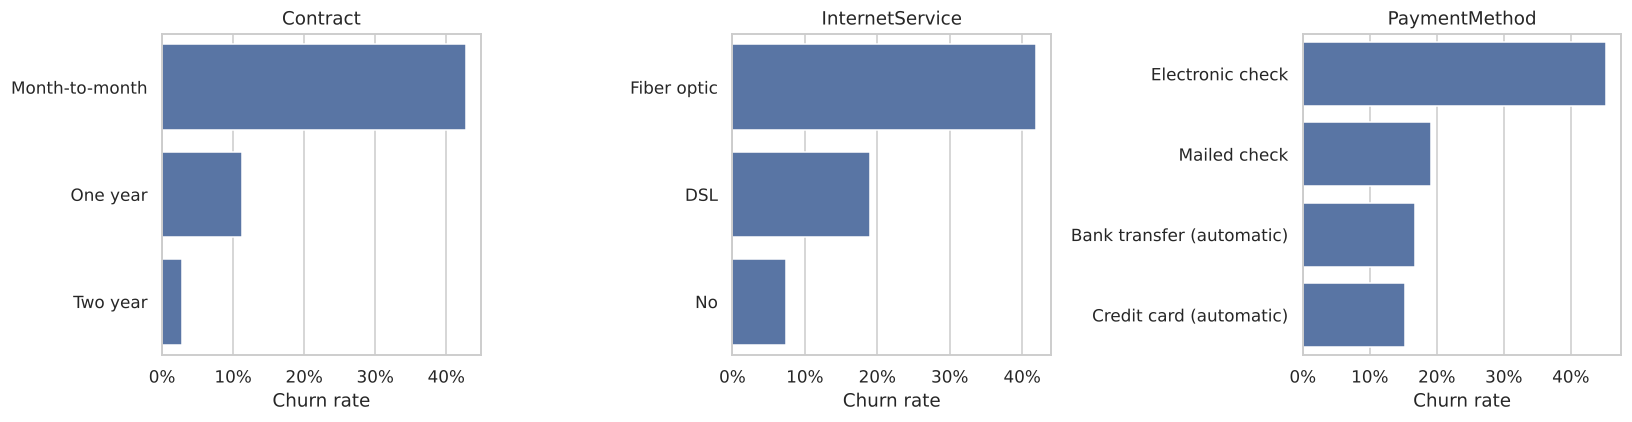

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#4C72B0")
    ax.set_xlabel("Churn rate"); ax.set_ylabel(""); ax.set_title(col)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(IMG / "churn_by_category.png", bbox_inches="tight"); plt.show()

Three things jump out:
- **Month-to-month contracts churn at ~43%**, compared to ~11% on one-year and ~3% on two-year contracts.
- **Fiber optic customers churn more than DSL**, even though fiber is the premium product. That points at
  price or service quality, not the technology itself.
- **Electronic check** payers churn far more than people on automatic payments.

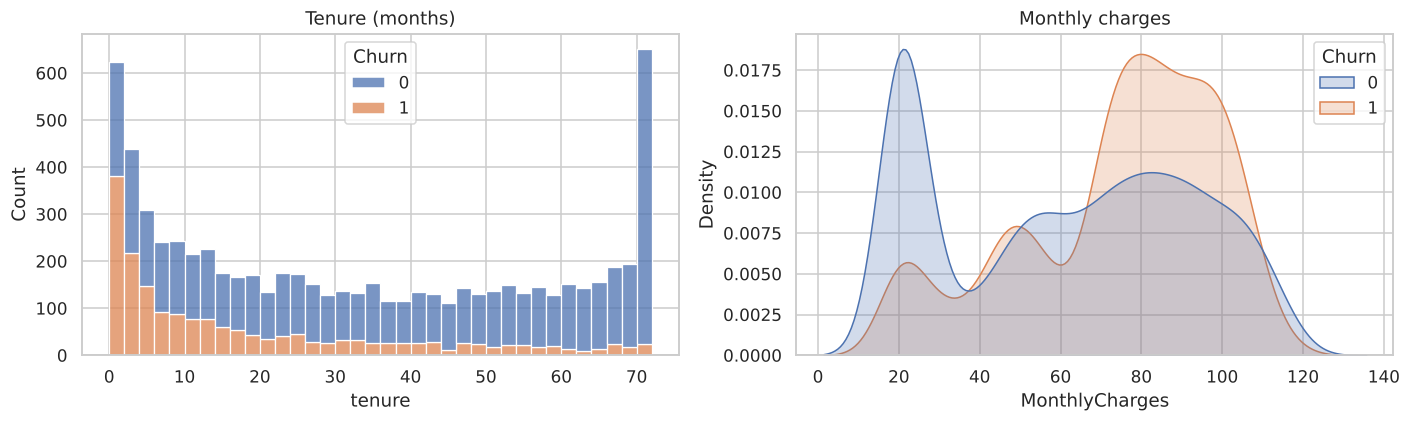

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure (months)")
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=axes[1])
axes[1].set_title("Monthly charges")
plt.tight_layout(); plt.savefig(IMG / "tenure_charges.png", bbox_inches="tight"); plt.show()

Churn is concentrated in the first few months: if a customer makes it past the first year they're much
more likely to stay. Churners also skew towards higher monthly bills (the $70-$105 range).

In [7]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
rates = {c: df[df[c] != "No internet service"].groupby(c)["Churn"].mean() for c in service_cols}
pd.DataFrame(rates).T.style.format("{:.1%}")

,No,Yes
OnlineSecurity,41.8%,14.6%
OnlineBackup,39.9%,21.5%
DeviceProtection,39.1%,22.5%
TechSupport,41.6%,15.2%
StreamingTV,33.5%,30.1%
StreamingMovies,33.7%,29.9%


Customers **without** online security or tech support churn at about 41-42%, vs ~15% for those who have
them. Streaming services barely matter. Security and support add-ons look like they make people "stickier".

## 3. Feature engineering

A few features based on what the EDA showed:
- `num_addons`: how many of the protection/support/streaming add-ons a customer has
- `tenure_group`: tenure bucketed into stages of the customer lifecycle
- `avg_monthly_spend`: TotalCharges / tenure. Comparing this to the current bill shows if the price went up
- `charge_increase`: current MonthlyCharges minus that historical average
- `auto_pay`: whether the payment method is automatic

In [8]:
def add_features(d):
    d = d.copy()
    d["num_addons"] = (d[service_cols] == "Yes").sum(axis=1)
    d["tenure_group"] = pd.cut(d["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                               labels=["0-6m", "7-12m", "1-2y", "2-4y", "4-6y"]).astype(str)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"].clip(lower=1), d["MonthlyCharges"])
    d["charge_increase"] = d["MonthlyCharges"] - d["avg_monthly_spend"]
    d["auto_pay"] = d["PaymentMethod"].str.contains("automatic").map({True: "Yes", False: "No"})
    return d

df = add_features(df)
df.groupby("num_addons")["Churn"].agg(["mean", "count"]).rename(columns={"mean": "churn_rate"}).style.format({"churn_rate": "{:.1%}"})

,churn_rate,count
num_addons,,
0,21.4%,2219
1,45.8%,966
2,35.8%,1033
3,27.4%,1118
4,22.3%,852
5,12.4%,571
6,5.3%,284


## 4. Train/test split and preprocessing

I keep 20% aside as a test set and don't touch it until the very end. Everything else (model choice,
tuning, threshold) is decided with cross-validation on the training set.

In [9]:
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("object").columns.tolist()
print(len(num_cols), "numeric:", num_cols)
print(len(cat_cols), "categorical")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
])

6 numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_addons', 'avg_monthly_spend', 'charge_increase']
18 categorical


## 5. Model comparison (5-fold CV)

In [10]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=pos_weight, eval_metric="logloss", random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, class_weight="balanced", random_state=SEED, verbose=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision", "f1"], n_jobs=1)
    rows.append({"model": name, "ROC-AUC": s["test_roc_auc"].mean(), "ROC-AUC std": s["test_roc_auc"].std(),
                 "PR-AUC": s["test_average_precision"].mean(), "F1": s["test_f1"].mean()})
cv_results = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
cv_results.style.format({c: "{:.3f}" for c in cv_results.columns if c != "model"})

,model,ROC-AUC,ROC-AUC std,PR-AUC,F1
0,Logistic Regression,0.847,0.011,0.660,0.628
1,Random Forest,0.845,0.009,0.656,0.634
2,LightGBM,0.842,0.011,0.653,0.635
3,XGBoost,0.840,0.008,0.650,0.631


All four land within about 0.007 AUC of each other, which is common for tabular data like this: most of the
signal sits in a handful of strong features (contract, tenure, internet type). Plain logistic regression
actually comes out on top with default settings. The untuned boosted trees are slightly overfitting, so I'll
tune XGBoost to see if it can beat that baseline, and keep logistic regression as the simpler fallback.

## 6. Hyperparameter tuning

In [11]:
xgb_pipe = Pipeline([("prep", preprocess), ("model", XGBClassifier(eval_metric="logloss", scale_pos_weight=pos_weight,
                                                                    random_state=SEED, n_jobs=-1))])
param_dist = {
    "model__n_estimators": [200, 300, 400, 600],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.5, 0.7, 0.8, 1.0],
    "model__gamma": [0, 0.5, 1, 2],
}
search = RandomizedSearchCV(xgb_pipe, param_dist, n_iter=40, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1)
search.fit(X_train, y_train)
print("Best CV ROC-AUC: {:.4f}".format(search.best_score_))
{k.replace("model__", ""): v for k, v in search.best_params_.items()}

Best CV ROC-AUC: 0.8499


{'subsample': 0.8,
 'n_estimators': 200,
 'min_child_weight': 1,
 'max_depth': 2,
 'learning_rate': 0.05,
 'gamma': 0,
 'colsample_bytree': 0.5}

## 7. Choosing a threshold

The default 0.5 cut-off isn't automatically the right one. Missing a churner (a lost customer) usually
costs more than giving a discount to someone who would have stayed anyway. I pick the threshold that
maximises F1 on **out-of-fold predictions from the training set**, so the test set stays clean.

In [12]:
from sklearn.model_selection import cross_val_predict
best = search.best_estimator_
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
threshold = float(thr[np.argmax(f1s[:-1])])
print(f"Chosen threshold: {threshold:.3f}")

Chosen threshold: 0.590


## 8. Final evaluation on the test set

In [13]:
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
test_auc = roc_auc_score(y_test, proba)
test_ap = average_precision_score(y_test, proba)
print(f"Test ROC-AUC: {test_auc:.3f}   Test PR-AUC: {test_ap:.3f}")
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"], digits=3))

Test ROC-AUC: 0.845   Test PR-AUC: 0.665
              precision    recall  f1-score   support

      Stayed      0.893     0.789     0.838      1035
     Churned      0.559     0.738     0.636       374

    accuracy                          0.776      1409
   macro avg      0.726     0.764     0.737      1409
weighted avg      0.804     0.776     0.784      1409



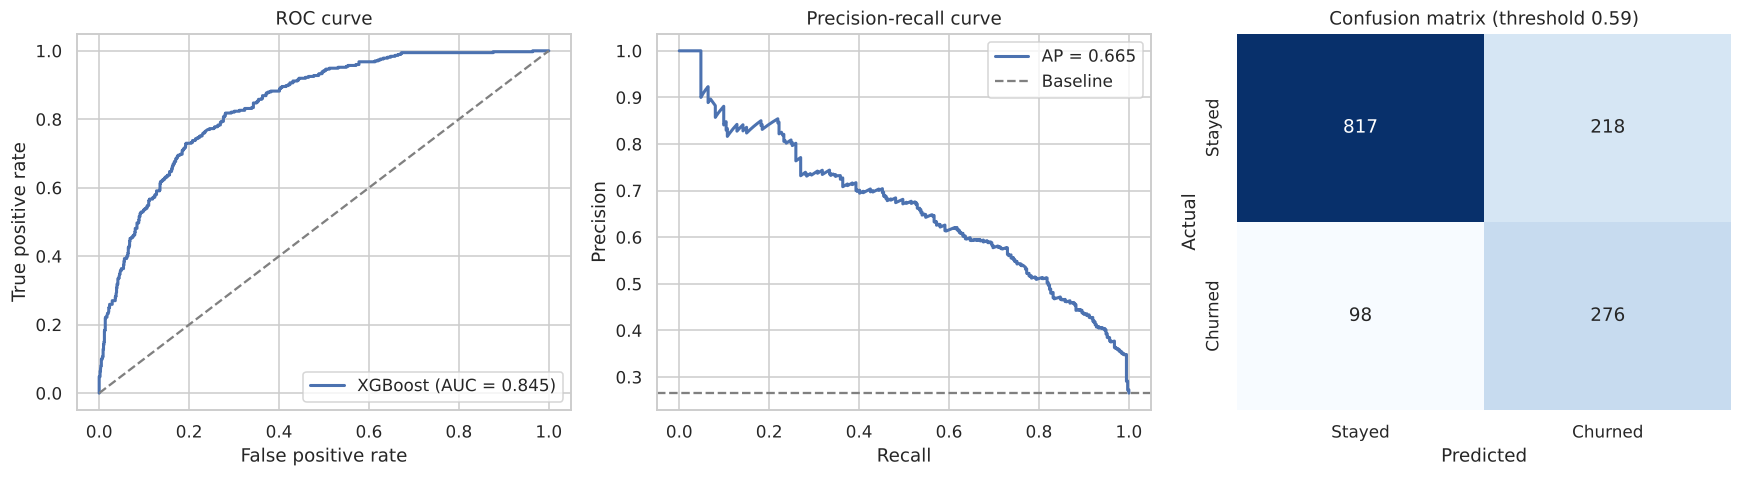

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, lw=2, label=f"XGBoost (AUC = {test_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve"); axes[0].legend()

p, r, _ = precision_recall_curve(y_test, proba)
axes[1].plot(r, p, lw=2, label=f"AP = {test_ap:.3f}")
axes[1].axhline(y_test.mean(), ls="--", color="grey", label="Baseline")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve"); axes[1].legend()

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
axes[2].set(xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix (threshold {threshold:.2f})")
plt.tight_layout(); plt.savefig(IMG / "evaluation.png", bbox_inches="tight"); plt.show()

## 9. What drives churn? (SHAP)

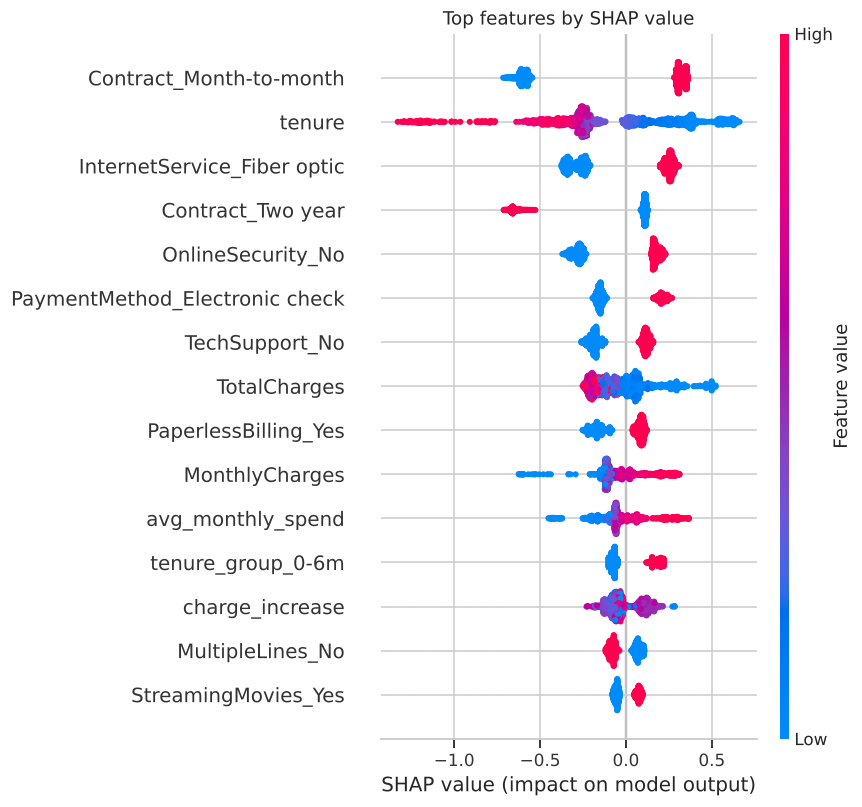

In [15]:
prep_fitted = best.named_steps["prep"]
model_fitted = best.named_steps["model"]
X_test_t = prep_fitted.transform(X_test)
feat_names = [n.split("__", 1)[1] for n in prep_fitted.get_feature_names_out()]
X_test_df = pd.DataFrame(X_test_t.toarray() if hasattr(X_test_t, "toarray") else X_test_t, columns=feat_names)
explainer = shap.TreeExplainer(model_fitted)
shap_values = explainer.shap_values(X_test_df)
shap.summary_plot(shap_values, X_test_df, max_display=15, show=False)
plt.title("Top features by SHAP value"); plt.tight_layout()
plt.savefig(IMG / "shap_summary.png", bbox_inches="tight"); plt.show()

In [16]:
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feat_names).sort_values(ascending=False)
importance.head(10).round(3)

Contract_Month-to-month           0.448
tenure                            0.352
InternetService_Fiber optic       0.276
Contract_Two year                 0.239
OnlineSecurity_No                 0.229
PaymentMethod_Electronic check    0.172
TechSupport_No                    0.152
TotalCharges                      0.128
PaperlessBilling_Yes              0.119
MonthlyCharges                    0.115
dtype: float32

The SHAP plot lines up with the EDA:
- **Month-to-month contract** is the biggest single push towards churn.
- **Short tenure** strongly increases risk; long tenure protects.
- **Fiber optic** and **high monthly charges** push risk up.
- **No online security / tech support** add risk, and `num_addons` captures the same "stickiness" effect.

## 10. What this means for a retention campaign

A model score is only useful if it changes who gets contacted. The cumulative gains chart below sorts test
customers by predicted risk and shows what share of all churners you'd reach by contacting the top X%.

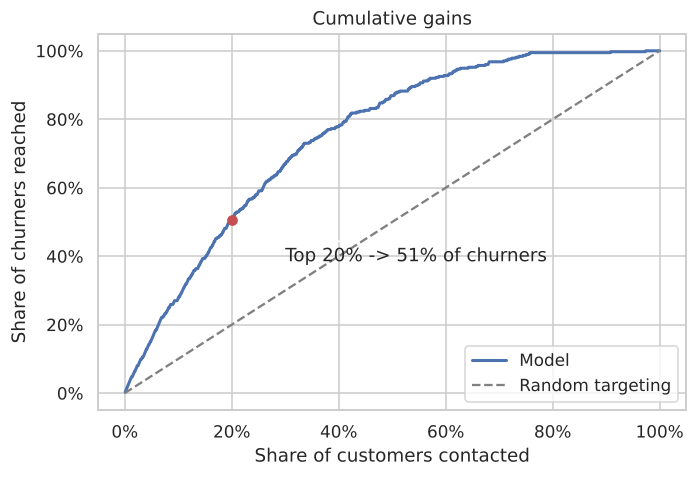

Contacting the riskiest 20% reaches 50.5% of churners; the riskiest 30% reaches 66.8%.


In [17]:
order = np.argsort(-proba)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
pct = np.arange(1, len(order) + 1) / len(order)
top20 = captured[int(0.2 * len(order)) - 1]
top30 = captured[int(0.3 * len(order)) - 1]

plt.figure(figsize=(6.5, 4.5))
plt.plot(pct, captured, lw=2, label="Model")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random targeting")
plt.scatter([0.2], [top20], zorder=5, color="#C44E52")
plt.annotate(f"Top 20% -> {top20:.0%} of churners", (0.2, top20), xytext=(0.3, top20 - 0.12),
             arrowprops=dict(arrowstyle="->"))
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.xlabel("Share of customers contacted"); plt.ylabel("Share of churners reached")
plt.title("Cumulative gains"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "gains_chart.png", bbox_inches="tight"); plt.show()
print(f"Contacting the riskiest 20% reaches {top20:.1%} of churners; the riskiest 30% reaches {top30:.1%}.")

## 11. Save the model and results

In [18]:
joblib.dump({"pipeline": best, "threshold": threshold}, "models/churn_model.joblib")
results = {
    "cv": cv_results.round(4).to_dict(orient="records"),
    "best_cv_auc": round(float(search.best_score_), 4),
    "threshold": round(threshold, 3),
    "test_roc_auc": round(float(test_auc), 4),
    "test_pr_auc": round(float(test_ap), 4),
    "test_f1": round(float(f1_score(y_test, pred)), 4),
    "test_recall": round(float((pred[y_test.values == 1] == 1).mean()), 4),
    "test_precision": round(float(y_test.values[pred == 1].mean()), 4),
    "top20_capture": round(float(top20), 4),
    "top30_capture": round(float(top30), 4),
    "top_features": importance.head(8).round(4).to_dict(),
}
Path("results").mkdir(exist_ok=True)
json.dump(results, open("results/metrics.json", "w"), indent=2)
results

{'cv': [{'model': 'Logistic Regression',
   'ROC-AUC': 0.847,
   'ROC-AUC std': 0.0109,
   'PR-AUC': 0.6602,
   'F1': 0.6275},
  {'model': 'Random Forest',
   'ROC-AUC': 0.8445,
   'ROC-AUC std': 0.0094,
   'PR-AUC': 0.6559,
   'F1': 0.6342},
  {'model': 'LightGBM',
   'ROC-AUC': 0.8425,
   'ROC-AUC std': 0.0108,
   'PR-AUC': 0.6528,
   'F1': 0.6352},
  {'model': 'XGBoost',
   'ROC-AUC': 0.8401,
   'ROC-AUC std': 0.0081,
   'PR-AUC': 0.6505,
   'F1': 0.6313}],
 'best_cv_auc': 0.8499,
 'threshold': 0.59,
 'test_roc_auc': 0.8448,
 'test_pr_auc': 0.6647,
 'test_f1': 0.6359,
 'test_recall': 0.738,
 'test_precision': 0.5587,
 'top20_capture': 0.5053,
 'top30_capture': 0.6684,
 'top_features': {'Contract_Month-to-month': 0.44830000400543213,
  'tenure': 0.3522999882698059,
  'InternetService_Fiber optic': 0.2761000096797943,
  'Contract_Two year': 0.23919999599456787,
  'OnlineSecurity_No': 0.22939999401569366,
  'PaymentMethod_Electronic check': 0.1720999926328659,
  'TechSupport_No': 0.152

## Takeaways

- Churn is mostly about **commitment and early experience**: month-to-month customers in their first year,
  especially on fiber with high bills and no support add-ons, are the ones leaving.
- Practical levers: nudge month-to-month customers towards annual plans (e.g. a discount for switching),
  bundle online security / tech support for new fiber customers, and push auto-pay over electronic checks.
- After tuning, XGBoost edges past logistic regression in CV (0.850 vs 0.847) and scores 0.845 ROC-AUC on unseen customers, and focusing a campaign on the top 20-30% of
  scores reaches roughly half to two-thirds of the people who'd actually leave.

**What I'd try next:** a proper cost-based threshold once real retention offer costs are known, survival
analysis to predict *when* someone will churn rather than just *if*, and checking calibration before the
scores get used as probabilities.